In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from numpy import linalg as LA
import copy
import networkx as nx
import random
from scipy.stats import spearmanr
plt.rcParams.update({'font.size': 17})
import pickle

#### Load data

In [2]:
young_liver_expr = pd.read_csv("MultiCens_young_liver_expr.csv")
young_brain_expr = pd.read_csv("MultiCens_young_brain_hypothalamus_expr.csv")
aged_liver_expr = pd.read_csv("MultiCens_aged_liver_expr.csv")
aged_brain_expr = pd.read_csv("MultiCens_aged_brain_hypothalamus_expr.csv")

# --- Load phenotype tables ---
with open("ModWGCNA_phenotype_tables.pkl", "rb") as f:
    pheno_dict = pickle.load(f)
young_liver_pheno = pheno_dict["young_liver"]
young_brain_pheno = pheno_dict["young_brain_hypothalamus"]
aged_liver_pheno = pheno_dict["aged_liver"]
aged_brain_pheno = pheno_dict["aged_brain_hypothalamus"]

#### Functions for data processing

In [3]:
def regress_out_confounds_df(expr_df: pd.DataFrame,
                             confounds: pd.DataFrame) -> pd.DataFrame:
    """
    Regress out confounding factors from every gene in an expression DataFrame.

    Parameters:
    -----------
    expr_df : pd.DataFrame
        Gene‐expression matrix, shape (n_samples, n_genes).
    confounds : pd.DataFrame
        Confounder matrix, shape (n_samples, n_covariates).
        Rows must align with expr_df.

    Returns:
    --------
    pd.DataFrame
        Residualized expression matrix, same shape and index/columns as expr_df.
    """
    # Build design matrix X (n_samples × (n_covariates + 1))
    X = confounds.copy()
    X['intercept'] = 1
    X_mat = X.values                          # shape (n_samples, p)
    
    # Response matrix Y (n_samples × n_genes)
    Y_mat = expr_df.values                    # shape (n_samples, g)

    # Solve for B in least squares: X B = Y  →  B = (X'X)^{-1} X' Y
    #   B will have shape (p, g)
    XtX_inv = np.linalg.inv(X_mat.T.dot(X_mat))
    B = XtX_inv.dot(X_mat.T).dot(Y_mat)

    # Predicted values: Y_hat = X B  (n_samples × g)
    Y_hat = X_mat.dot(B)

    # Residuals: Y_resid = Y − Y_hat
    resid = Y_mat - Y_hat

    # Wrap back into DataFrame
    resid_df = pd.DataFrame(resid,
                            index=expr_df.index,
                            columns=expr_df.columns)
    return resid_df

def select_top_variant_genes(expression: pd.DataFrame, max_genes: int) -> pd.Index:
    """
    Select most variant genes based on standard deviation.

    Parameters:
    expression: DataFrame of shape (samples, genes)
    max_genes: maximum number of genes to select

    Returns:
    top_genes: Index of selected genes
    """
    stds = expression.std(axis=0)
    top = stds.nlargest(max_genes).index
    return top

In [4]:
liver_expr = pd.concat([young_liver_expr,aged_liver_expr])
liver_expr = liver_expr.set_index('Unnamed: 0')
brain_expr = pd.concat([young_brain_expr,aged_brain_expr])
brain_expr = brain_expr.set_index('Unnamed: 0')

liver_pheno = pd.concat([young_liver_pheno,aged_liver_pheno])
brain_pheno = pd.concat([young_brain_pheno,aged_brain_pheno])

liver_hvgs = select_top_variant_genes(liver_expr, max_genes=10000)
brain_hvgs = select_top_variant_genes(brain_expr, max_genes=10000)

In [5]:
common_hvgs = list(set(liver_hvgs).intersection(set(brain_hvgs)))
liver_pheno.drop(columns=['AGE','SAMPID_2'],inplace=True)
brain_pheno.drop(columns=['AGE','SAMPID_2'],inplace=True)

liver_corrected = regress_out_confounds_df(liver_expr[common_hvgs],liver_pheno)
brain_corrected = regress_out_confounds_df(brain_expr[common_hvgs],brain_pheno)

#### Compute spearman correlation (abs)

In [6]:
import numpy as np
import pandas as pd

def spearman_cross_df(X: pd.DataFrame, Y: pd.DataFrame) -> pd.DataFrame:
    """
    Compute Spearman correlation between all genes in X and all genes in Y
    without using scipy.

    Returns: genes_X × genes_Y matrix
    """
    assert X.shape[0] == Y.shape[0], "Samples must match"

    # Rank across samples (column-wise)
    X_rank = X.rank(axis=0, method="average").to_numpy()
    Y_rank = Y.rank(axis=0, method="average").to_numpy()

    # Center
    X_rank -= X_rank.mean(axis=0)
    Y_rank -= Y_rank.mean(axis=0)

    # Pearson on ranks
    num = X_rank.T @ Y_rank
    den = np.sqrt(
        np.sum(X_rank**2, axis=0)[:, None] *
        np.sum(Y_rank**2, axis=0)[None, :]
    )

    corr = num / den

    return pd.DataFrame(corr, index=X.columns, columns=Y.columns)


In [7]:
import numpy as np
import pandas as pd

def assemble_2layer_supra(A: pd.DataFrame, B: pd.DataFrame, C: pd.DataFrame):
    """
    Assemble 2-layer supra-adjacency:
      M = [[ A, C.T ],
           [ C, B  ]]
    A, B, C must be (n_genes x n_genes) and share the same gene order/index.
    Returns a pandas.DataFrame of shape (2n, 2n) with row/col labels prefixed by layer.
    """
    # checks
    if A.shape != B.shape or A.shape != C.shape:
        raise ValueError("A, B and C must be same square shape (n x n).")
    if not (A.index.equals(B.index) and A.index.equals(C.index)):
        raise ValueError("A, B and C must have identical index/columns (same gene order).")

    genes = list(A.index)
    n = len(genes)

    # build numpy block matrix
    top_left = A.values
    bottom_right = B.values
    bottom_left = C.values
    top_right = C.values.T

    M_np = np.zeros((2*n, 2*n), dtype=top_left.dtype)
    M_np[:n, :n] = top_left
    M_np[:n, n:] = top_right
    M_np[n:, :n] = bottom_left
    M_np[n:, n:] = bottom_right

    # build labels: prefix gene names with layer id so names are unique
    labels = [f"{g}" for g in genes] + \
             [f"{g}" for g in genes]

    M = pd.DataFrame(M_np, index=labels, columns=labels)
    return M


In [8]:
young_liver_corr, _ = spearmanr(liver_corrected[liver_corrected.index.isin(young_liver_expr['Unnamed: 0'])].values,axis=0)
young_liver_corr = pd.DataFrame(young_liver_corr, index=liver_corrected.columns, columns=liver_corrected.columns)

young_brain_corr, _ = spearmanr(brain_corrected[brain_corrected.index.isin(young_brain_expr['Unnamed: 0'])].values,axis=0)
young_brain_corr = pd.DataFrame(young_brain_corr, index=brain_corrected.columns, columns=brain_corrected.columns)

young_C_liver_brain = spearman_cross_df(
    liver_corrected[liver_corrected.index.isin(young_liver_expr['Unnamed: 0'])],
    brain_corrected[brain_corrected.index.isin(young_brain_expr['Unnamed: 0'])]
)

aged_liver_corr, _ = spearmanr(liver_corrected[liver_corrected.index.isin(aged_liver_expr['Unnamed: 0'])].values,axis=0)
aged_liver_corr = pd.DataFrame(aged_liver_corr, index=liver_corrected.columns, columns=liver_corrected.columns)

aged_brain_corr, _ = spearmanr(brain_corrected[brain_corrected.index.isin(aged_brain_expr['Unnamed: 0'])].values,axis=0)
aged_brain_corr = pd.DataFrame(aged_brain_corr, index=brain_corrected.columns, columns=brain_corrected.columns)

aged_C_liver_brain = spearman_cross_df(
    liver_corrected[liver_corrected.index.isin(aged_liver_expr['Unnamed: 0'])],
    brain_corrected[brain_corrected.index.isin(aged_brain_expr['Unnamed: 0'])]
)

In [9]:
young_supra = assemble_2layer_supra(young_liver_corr, young_brain_corr, 
                              young_C_liver_brain)
aged_supra = assemble_2layer_supra(aged_liver_corr, aged_brain_corr, 
                              aged_C_liver_brain)

#### MultiCens functions

In [10]:
# MultiCens: local centrality
def local_centrality(A_tilde_full, num_layers, target_tissue, target_gene_indices, p):
    print("target tissue id")
    print(target_tissue)
    print("local_centrality")
    #A_tilde_full = A_tilde_full/np.sum(A_tilde_full, axis=0)
    #A_tilde_full = A_tilde_full/LA.norm(A_tilde_full)
    num_target_genes = int(np.shape(target_gene_indices)[0])
    n = int(np.shape(A_tilde_full)[0]/num_layers)
    N = int(np.shape(A_tilde_full)[0])
    A_tilde = np.zeros_like(A_tilde_full, dtype=np.float32)
    
    for i in range(num_layers):
        A_tilde[(i*n):((i+1)*n),(i*n):((i+1)*n)] = A_tilde_full[(i*n):((i+1)*n),(i*n):((i+1)*n)]
    
    
    #np.fill_diagonal(A_tilde, 0.0)
    
    ones_t = np.ones((N,))/N
    l = np.copy(ones_t)
    l_new = np.copy(ones_t)
    
    count = 0
    current_angle = np.zeros(3,)
    print("local centrality computation starts")
    while(count<70):
        print(count)
        count = count + 1
        l_new = (p* ((A_tilde).dot(l))) + (1-p)*ones_t
        current_angle[0] = current_angle[1]
        current_angle[1] = current_angle[2]
        current_angle[2] = angle_between(l, l_new)
        print(current_angle)
        if(((current_angle[0] == current_angle[1]) and (current_angle[1] == current_angle[2])) or (current_angle[2] == 0)):
            break
        l = copy.deepcopy(l_new)
        #l = copy.deepcopy(l_new)/LA.norm(l_new)
    print("l values")
    print(l)
    #new_l = l/l.sum()# + l_tt/l_tt.sum()
    new_l = copy.deepcopy(l)
    
    for i in range(num_layers):
        l[(i*n):((i+1)*n)] = l[(i*n):((i+1)*n)]/l[(i*n):((i+1)*n)].sum()
    return new_l


# MultiCens: global centrality
def global_centrality(A_tilde_full, num_layers, target_tissue, target_gene_indices, p):
    l = local_centrality(A_tilde_full, num_layers, target_tissue, target_gene_indices, p) #last checkpoint
    A_tilde = copy.deepcopy(A_tilde_full)
    #A_tilde = A_tilde_full/np.sum(A_tilde_full, axis=0)
    N = int(np.shape(A_tilde)[0])
    n = int(N/num_layers)
    print("A_tilde sums")
    print(np.sum(A_tilde[0,:]))
    print(np.sum(A_tilde[:,0]))
        
    A = np.zeros_like(A_tilde_full, dtype=np.float32)
    C = np.zeros_like(A_tilde_full, dtype=np.float32)
    A[:n,:n] = copy.deepcopy(A_tilde[:n,:n])
    A[n:(2*n),n:(2*n)] = copy.deepcopy(A_tilde[n:(2*n),n:(2*n)])
    A[(2*n):(3*n),(2*n):(3*n)] = copy.deepcopy(A_tilde[(2*n):(3*n),(2*n):(3*n)])
    A[(3*n):(4*n),(3*n):(4*n)] = copy.deepcopy(A_tilde[(3*n):(4*n),(3*n):(4*n)])
    C = A_tilde - A
    
    
    print("finding global centrality ")
    
    ones_t = np.ones((N,))/N
    g = copy.deepcopy(ones_t)
    g_new = copy.deepcopy(ones_t)
    
    
    counter = 0
    current_angle = np.zeros(3,)
    
    while(counter<150):
        g_new = (p * ((A+C).dot(g) + (C.dot(l)) )) + ((1-p)*ones_t)

        current_angle[0] = current_angle[1]
        current_angle[1] = current_angle[2]
        current_angle[2] = angle_between(g, g_new)
        print(current_angle)
        if(((current_angle[0] == current_angle[1]) and (current_angle[1] == current_angle[2])) or (current_angle[2] == 0)):
            break
        g = copy.deepcopy(g_new)
        #g = copy.deepcopy(g_new)/LA.norm(g_new)
        counter+=1
        print(counter)
        print(np.sum(g))
    
    new_g = copy.deepcopy(g)
    g_fresh = copy.deepcopy(g)
    new_g = new_g/new_g.sum()
    g_fresh = g_fresh/g_fresh.sum()
    return l, new_g


# MultiCens: target-layer centrality
def target_layer_centrality(A_tilde_full, num_layers, target_tissue, target_gene_indices, p):
    l = local_centrality(A_tilde_full, num_layers, target_tissue, target_gene_indices, p) #last checkpoint
    #A_tilde = copy.deepcopy(A_tilde_full)
    A_tilde = A_tilde_full/np.sum(A_tilde_full, axis=0)
    N = int(np.shape(A_tilde)[0])
    n = int(N/num_layers)
    print("A_tilde sums")
    print(np.sum(A_tilde[0,:]))
    print(np.sum(A_tilde[:,0]))
        
    A = np.zeros_like(A_tilde_full, dtype=np.float32)
    C = np.zeros_like(A_tilde_full, dtype=np.float32)
    A[:n,:n] = copy.deepcopy(A_tilde[:n,:n])
    A[n:,n:] = copy.deepcopy(A_tilde[n:,n:])
    C[:n,n:] = copy.deepcopy(A_tilde[:n,n:])
    C[n:,:n] = copy.deepcopy(A_tilde[n:,:n])
    
    
    print("finding target layer centrality for layer " + str(target_tissue))
    
    ones_t = np.zeros((N,))
    ones_t[int(n*target_tissue):] = 1/N
    g = copy.deepcopy(ones_t)
    g_new = copy.deepcopy(ones_t)
    
    
    counter = 0
    current_angle = np.zeros(3,)
    while(counter<70):
        g_new = (p * ((A+C).dot(g) + (C.dot(l)) )) + ((1-p)*ones_t)

        current_angle[0] = current_angle[1]
        current_angle[1] = current_angle[2]
        current_angle[2] = angle_between(g, g_new)
        print(current_angle)
        if(((current_angle[0] == current_angle[1]) and (current_angle[1] == current_angle[2])) or (current_angle[2] == 0)):
            break
        g = copy.deepcopy(g_new)
        #g = copy.deepcopy(g_new)/LA.norm(g_new)
        counter+=1
        print(counter)
        print(np.sum(g))
    new_g = copy.deepcopy(g)
    if target_tissue == 1:
        print("Found target set centrality")
        new_g[:n] = g[:n]/g[:n].max()
    elif target_tissue == 0:
        new_g[n:] = g[n:]/g[n:].max()
        print("Found source set centrality")
    else:
        print("invalid target tissue")
    return new_g

# Interlayer degree using a query set of nodes

def interlayer_target(A_tilde_full, num_layers, target_tissue, target_gene_indices, p):
    A_tilde = copy.deepcopy(A_tilde_full)
    #A_tilde = A_tilde_full/np.sum(A_tilde_full, axis=0)
    N = int(np.shape(A_tilde)[0])
    n = int(N/num_layers)
    print("A_tilde sums")
    print(np.sum(A_tilde[0,:]))
    print(np.sum(A_tilde[:,0]))
        
    A = np.zeros_like(A_tilde_full, dtype=np.float32)
    C = np.zeros_like(A_tilde_full, dtype=np.float32)
    A[:n,:n] = copy.deepcopy(A_tilde[:n,:n])
    A[[x + n for x in target_gene_indices], [x + n for x in target_gene_indices]] = copy.deepcopy(A_tilde[[x + n for x in target_gene_indices],[x + n for x in target_gene_indices]])
    C[:, [x + n for x in target_gene_indices]] = A_tilde[:, [x + n for x in target_gene_indices]]
    C[[x + n for x in target_gene_indices],:] = A_tilde[[x + n for x in target_gene_indices],:]
    
    A_dash = A + C
    print("finding versatility target centrality ")
    
    zeros_t = np.zeros((N,))/N
    g = copy.deepcopy(zeros_t)
    g = np.sum(A_dash, axis=1)
    return g


# Interlayer degree without using a query-set of nodes
def interlayer(A_tilde_full, num_layers, target_tissue, target_gene_indices, p):
    A_tilde = copy.deepcopy(A_tilde_full)
    #A_tilde = A_tilde_full/np.sum(A_tilde_full, axis=0)
    N = int(np.shape(A_tilde)[0])
    n = int(N/num_layers)
    
    zeros_t = np.zeros((N,))/N
    g = copy.deepcopy(zeros_t)
    g = np.sum(A_tilde, axis=1)
    return g

# Basic methods: These will be used while computing the centrality vector
def unit_vector(vector):
    """ Returns the unit vector of the vector.  """
    return vector / np.linalg.norm(vector)

def angle_between(v1, v2):
    """ Returns the angle in radians between vectors 'v1' and 'v2'::

            >>> angle_between((1, 0, 0), (0, 1, 0))
            1.5707963267948966
            >>> angle_between((1, 0, 0), (1, 0, 0))
            0.0
            >>> angle_between((1, 0, 0), (-1, 0, 0))
            3.141592653589793
    """
    v1_u = unit_vector(v1)
    v2_u = unit_vector(v2)
    return np.arccos(np.clip(np.dot(v1_u, v2_u), -1.0, 1.0))

In [11]:
# MultiCens local-set centrality

def right_new_local_centrality_st(A_tilde_full, num_layers, target_tissue, target_gene_indices, p):
    print("target tissue id")
    print(target_tissue)
    print("right_new_local_centrality")
    A_tilde_full = A_tilde_full/np.sum(A_tilde_full, axis=0)
    #A_tilde_full = A_tilde_full/LA.norm(A_tilde_full)
    num_target_genes = int(np.shape(target_gene_indices)[0])
    n = int(np.shape(A_tilde_full)[0]/num_layers)
    N = int(np.shape(A_tilde_full)[0])
    A_tilde = np.zeros_like(A_tilde_full, dtype=np.float32)
    
    if target_tissue == 1:
        A_tilde[n:,n:] = A_tilde_full[n:,n:]
    elif target_tissue == 0:
        A_tilde[:n,:n] = A_tilde_full[:n,:n]
    else:
        print("wrong target tissue")
    np.fill_diagonal(A_tilde, 0.0)
    #A_tilde = A_tilde/LA.norm(A_tilde)
    
    ones_t = np.zeros((N,))
    ones_t[(np.asarray(target_gene_indices, dtype= np.int32) + int(n*target_tissue))] = 1/len(target_gene_indices)
    l = np.copy(ones_t)
    l_new = np.copy(ones_t)
    
    count = 0
    current_angle = np.zeros(3,)
    print("local centrality computation starts")
    while(count<200):
        print(count)
        count = count + 1
        l_new = (p* ((A_tilde).dot(l))) + (1-p)*ones_t
        current_angle[0] = current_angle[1]
        current_angle[1] = current_angle[2]
        current_angle[2] = angle_between(l, l_new)
        print(current_angle)
        if(((current_angle[1] == current_angle[2])) or (current_angle[2] == 0)):
            break
        l = copy.deepcopy(l_new)
        #l = copy.deepcopy(l_new)/LA.norm(l_new)
    print("l values")
    print(l)
    #new_l = l/l.sum()# + l_tt/l_tt.sum()
    new_l = copy.deepcopy(l)
    if target_tissue == 0:
        print("Found local centrality for target set centrality")
        new_l[:n] = l[:n]/l[:n].sum()
    elif target_tissue == 1:
        new_l[n:] = l[n:]/l[n:].sum()
        print("Found local centrality for source set centrality")
    else:
        print("invalid target tissue")
    print("Target genes")
    print(target_gene_indices)
    return new_l

# MultiCens: Query-set centrality
def right_target_global_centrality_t(A_tilde_full, num_layers, target_tissue, target_gene_indices, p):
    l = right_new_local_centrality_st(A_tilde_full, num_layers, target_tissue, target_gene_indices, p) #last checkpoint
    #A_tilde = copy.deepcopy(A_tilde_full)
    A_tilde = A_tilde_full/np.sum(A_tilde_full, axis=0)
    N = int(np.shape(A_tilde)[0])
    n = int(N/num_layers)
    print("A_tilde sums")
    print(np.sum(A_tilde[0,:]))
    print(np.sum(A_tilde[:,0]))
        
    A = np.zeros_like(A_tilde_full, dtype=np.float32)
    C = np.zeros_like(A_tilde_full, dtype=np.float32)
    A[:n,:n] = copy.deepcopy(A_tilde[:n,:n])
    A[n:,n:] = copy.deepcopy(A_tilde[n:,n:])
    C[:n,n:] = copy.deepcopy(A_tilde[:n,n:])
    C[n:,:n] = copy.deepcopy(A_tilde[n:,:n])
    
    
    print("finding source global centrality for layer " + str(target_tissue))
    
    ones_t = np.zeros((N,))
    ones_t[(np.asarray(target_gene_indices, dtype= np.int32) + int(n*target_tissue))] = 1/len(target_gene_indices)
    g = copy.deepcopy(ones_t)
    g_new = copy.deepcopy(ones_t)
    
    
    counter = 0
    current_angle = np.zeros(3,)
    while(counter<200):
        g_new = (p * ((A+C).dot(g) + (C.dot(l)) )) + ((1-p)*ones_t)

        current_angle[0] = current_angle[1]
        current_angle[1] = current_angle[2]
        current_angle[2] = angle_between(g, g_new)
        print(current_angle)
        if(((current_angle[1] == current_angle[2])) or (current_angle[2] == 0)):
            break
        g = copy.deepcopy(g_new)
        #g = copy.deepcopy(g_new)/LA.norm(g_new)
        counter+=1
        print(counter)
        print(np.sum(g))
    new_g = copy.deepcopy(g)
    if target_tissue == 1:
        print("Found target set centrality")
        new_g[:n] = g[:n]/g[:n].max()
    elif target_tissue == 0:
        new_g[n:] = g[n:]/g[n:].max()
        print("Found source set centrality")
    else:
        print("invalid target tissue")
    return l, new_g

In [12]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Generate recall-at-k hits
def get_hits(k_range, ranked_genes, ground_truth_genes):
    hits = np.zeros_like(k_range)
    current_hit_count = 0
    for idx, i in enumerate(k_range):
        if ranked_genes[i] in ground_truth_genes:
            current_hit_count += 1
        hits[idx] = current_hit_count
    return hits

def plot_target_layer_k_curve(genes, target_layer_cen_vector, ground_truth_genes, 
                              secreted_proteins_file="/home/s4634945/soft_links/Q5058/IOC/Benchmark_datasets/MultiCens/GO0002790.txt"):
    """
    genes: list of all gene names in the layer
    target_layer_cen_vector: centrality vector from target_layer_centrality
    ground_truth_genes: list of true positive genes (e.g., known secreted proteins)
    secreted_proteins_file: optional path to GO/benchmark secreted genes file
    """
    n = len(genes)

    # Load secreted proteins if provided
    if secreted_proteins_file is not None:
        secreted_proteins = pd.read_csv(secreted_proteins_file, header=None).iloc[:,0].str.upper().tolist()
    else:
        secreted_proteins = []

    # Build dataframe and sort by centrality
    target_layer_order = target_layer_cen_vector[:n].argsort()
    target_layer_ranks = target_layer_order.argsort()
    target_layer_d = {
        'gene_name': genes,
        'centrality': target_layer_cen_vector[:n],
        'rank': n - target_layer_ranks  # higher centrality -> higher rank
    }
    target_layer_results = pd.DataFrame(data=target_layer_d).sort_values(by='centrality', ascending=False)
    target_layer_ranked_genes = target_layer_results['gene_name'].tolist()

    # Filter for secreted proteins if provided
    filtered_results = target_layer_results[target_layer_results['gene_name'].isin(secreted_proteins)]
    filtered_ranked_genes = filtered_results['gene_name'].tolist()

    # Compute recall-at-k
    k_range = np.arange(n)
    target_layer_hits = get_hits(k_range, target_layer_ranked_genes, ground_truth_genes)

    # Random baseline curve
    random_curve = np.cumsum(np.full((n,), target_layer_hits[-1]/n))

    # Plot recall-at-k
    plot_variables = {
        'Target-layer centrality': target_layer_hits,
        'Random baseline': random_curve
    }
    plot_df = pd.DataFrame(plot_variables)
    sns.lineplot(data=plot_df)
    plt.xlabel("Top k predictions")
    plt.ylabel("Cumulative hits / Recall")
    plt.xticks(np.arange(0, n, max(1, n//5)))

    return target_layer_results, filtered_results, plot_df


In [13]:
brain_secreted_genes = [
    # Classical HPA & neuroendocrine hormones (core)
    "CRH", "CRHR1L", "AVP", "OXT", "TRH", "GHRH", "SST", "POMC", "ACTH", "MSH",
    "NPY", "AGRP", "PENK", "PDYN", "PNOC", "GAL", "GALP", "TAC1", "TAC3", "TAC4",
    "VIP", "ADCYAP1", "RELN",
    # [NEW] Pituitary hormones with direct liver effects
    "TSHB",  # Thyroid stimulating hormone (targets hepatic TSHR)
    "PRL",   # Prolactin (regulates hepatic lipid metabolism)
    
    # Brain-derived growth factors & metabolic hormones
    "BDNF", "NGF", "NTF3", "NTF4", "IGF1", "IGF2", "FGF1", "FGF2", "FGF8", "FGF17",
    "FGF18", "FGF21", "VEGFA", "VEGFB", "PDGFA", "PDGFB", "TGFB1", "TGFB2", "TGFB3",
    "BMP2", "BMP4", "BMP7",
    
    # Appetite, energy balance & systemic metabolism
    # Note: INS removed (Pancreatic)
    "LEP", "LEPRL", "INSL3", "INSL5", "ADIPOQ", "APLN", "GDF15", "CARTPT",
    "UCP2", "UCP3",
    
    # Cytokines & immune–neural mediators (brain-expressed)
    "IL1B", "IL6", "IL10", "IL18", "TNF", "IFNG", "CSF1", "CSF2", "CXCL12", "CXCL14",
    "CCL2", "CCL5", "CCL19", "CCL21",
    
    # Wnt, Hedgehog, Notch & morphogens (systemic effects)
    # Caution: WNTs are typically paracrine (local), not endocrine.
    "WNT1", "WNT3", "WNT3A", "WNT5A", "WNT7A", "WNT7B", "SHH", "IHH", "DHH",
    "DLL1", "DLL3", "DLL4", "JAG1", "JAG2",
    
    # Secreted enzymes & modulators
    "ACE", "ACE2", "REN", "AGT", "KLK1", "ENPP2", "MMP2", "MMP9", "PLAT", "PLA2G4A"
]

brain_to_liver_receptor_genes = [
    # Neuropeptide & hormone receptors
    "CRHR1", "CRHR2", "AVPR1A", "AVPR1B", "OXTR", "GHR", "GHRHR", "SSTR1", "SSTR2",
    "SSTR3", "SSTR5", "NPY1R", "NPY2R", "NPY5R", "MC4R", "VIPR1", "VIPR2",
    "ADCYAP1R1", "GALR1", "GALR2",
    # [NEW] Receptors for new additions
    "TSHR",  # Receptor for TSH
    "PRLR",  # Receptor for Prolactin
    
    # Growth factor & metabolic receptors
    "IGF1R", "IGF2R", "INSR", "FGFR1", "FGFR2", "FGFR3", "FGFR4", "KLB", "PDGFRA",
    "PDGFRB", "VEGFR1", "VEGFR2", "TGFBR1", "TGFBR2", "BMPR1A", "BMPR1B", "BMPR2",
    
    # Cytokine & inflammatory receptors
    "IL1R1", "IL6R", "IL6ST", "IL10RA", "IL10RB", "TNFRSF1A", "TNFRSF1B", "IFNGR1",
    "IFNGR2", "CSF1R", "CSF2RA", "CXCR4", "CCR2", "CCR5", "CCR7",
    
    # Wnt / Notch / Hedgehog receptors
    "FZD1", "FZD2", "FZD4", "FZD6", "LRP5", "LRP6", "PTCH1", "SMO", "NOTCH1",
    "NOTCH2", "NOTCH3", "ROR1", "ROR2",
    
    # Metabolic & nutrient sensing receptors
    "LEPR", "ADIPOR1", "ADIPOR2", "APJ", "GPR120", "GPR40", "GPR41", "GPR43",
    "GPR84", "FFAR1", "FFAR2", "FFAR3",
    
    # Nuclear hormone receptors (signal integration layer)
    "NR3C1", "NR3C2", "THRA", "THRB", "ESR1", "ESR2", "PPARA", "PPARG", "PPARD",
    "FXR", "LXR", "RXRA"
]

hepatokine_genes = [
    # Classical hepatokines (core)
    "FGF21", "ANGPTL3", "ANGPTL4", "ANGPTL6", "AHSG", "FETUB", "LECT2", "SEPP1",
    "HP", "ORM1", "ORM2", "APOC1", "APOC3", "APOC4", "APOA1", "APOA4", "APOB",
    # [NEW] High-confidence hepatokines
    "HAMP",    # Hepcidin (Master iron regulator)
    "LCN2",    # Lipocalin-2 (Regulates appetite via brain)
    "INHBE",   # Activin E (Liver-derived metabolic regulator)
    "ANGPTL8", # Betatrophin (Lipid metabolism)
    "MANF",    # Mesencephalic astrocyte-derived neurotrophic factor (Feeding-induced hepatokine)
    
    # Glucose, lipid & energy metabolism regulators
    # Note: INS removed (Pancreatic), FGF19 removed (Intestinal)
    "GDF15", "IGF1", "IGF2", "INHBA", "INHBB", "BMP9", "BMP10", "TGFB1",
    "TGFB2", "TGFB3", "CTGF", "TSLP",
    
    # Bile acid & cholesterol signalling
    "CYP7A1", "CYP8B1", "CYP27A1", "NR1H4", "SULT2A1", "UGT1A1", "ABCB11",
    
    # Inflammatory & immune mediators
    "IL1A", "IL1B", "IL6", "IL18", "TNF", "IFNG", "CSF1", "CSF3", "CXCL1", "CXCL2",
    "CXCL8", "CXCL10", "CCL2", "CCL5",
    
    # Coagulation, complement & plasma proteins
    "ALB", "TF", "TTR", "FGA", "FGB", "FGG", "CFD", "C3", "C4A", "C4B", "C5",
    "SERPINA1", "SERPINC1", "SERPINF1",
    
    # Secreted enzymes & metabolic modulators
    "ACE", "ACE2", "REN", "AGT", "ENPP1", "ENPP2", "MMP2", "MMP7", "MMP9", "PLA2G7"
]

liver_to_brain_receptor_genes = [
    # Growth factor & hepatokine receptors
    "FGFR1", "FGFR2", "FGFR3", "KLB", "IGF1R", "IGF2R", "INSR", "TGFBR1", "TGFBR2",
    "BMPR1A", "BMPR1B", "BMPR2",
    # [NEW] Specific receptors for hepatokines
    "GFRAL",    # Receptor for GDF15 (Hindbrain/Area Postrema)
    "SLC22A17", # Receptor for LCN2 (Lipocalin-2)
    "ACVR1C",   # Receptor involved in Activin signaling
    "ACVR2A",   # Receptor involved in Activin signaling
    
    # Cytokine & immune receptors (neuroinflammation axis)
    "IL1R1", "IL6R", "IL6ST", "IL18R1", "TNFRSF1A", "TNFRSF1B", "IFNGR1", "IFNGR2",
    "CSF1R", "CSF3R", "CXCR2", "CXCR3", "CCR2", "CCR5",
    
    # Metabolic & nutrient sensors (key brain targets)
    "LEPR", "ADIPOR1", "ADIPOR2", "FFAR1", "FFAR2", "FFAR3", "GPR120", "GPR40",
    "GPR84", "MC4R", "NPY1R", "NPY5R",
    
    # Nuclear hormone & bile acid receptors
    "NR3C1", "NR1H4", "NR1H3", "NR1H2", "THRA", "THRB", "ESR1", "ESR2", "PPARA",
    "PPARG", "RXRA",
    
    # Neurovascular & BBB interface receptors
    "LRP1", "LRP2", "AGER", "RAGE", "PECAM1", "ICAM1", "VCAM1", "PLVAP",
    
    # GPCRs sensing circulating factors
    "GPR37", "GPR39", "GPR50", "GPR52", "GPR65", "GPR88"
]

#### Running MultiCens

##### Young

In [14]:
N = int(young_supra.shape[0])
L = 2
n = int(N/L)

genes = list(young_supra.columns[:n])
source_genes = hepatokine_genes
target_genes = liver_to_brain_receptor_genes

print("Statistics of the ground truth data")
print("Number of genes: ", len(genes))
print("Number of target genes: ", len(target_genes))
print("Number of source genes: ", len(source_genes))
#print(genes)


common_source_genes = np.intersect1d(genes, source_genes)
common_target_genes = np.intersect1d(genes, target_genes)

print("Number of target genes present in the data: ", len(common_target_genes))
print("Number of source genes present in the data: ", len(common_source_genes))

target_genes_indices = [i for i, e in enumerate(genes) if e in common_target_genes]
source_genes_indices = [i for i, e in enumerate(genes) if e in common_source_genes]

Statistics of the ground truth data
Number of genes:  7510
Number of target genes:  67
Number of source genes:  79
Number of target genes present in the data:  36
Number of source genes present in the data:  23


target tissue id
1
right_new_local_centrality
local centrality computation starts
0
[0.         0.         0.34872067]
1
[0.         0.34872067 0.11650861]
2
[0.34872067 0.11650861 0.06478296]
3
[0.11650861 0.06478296 0.03806837]
4
[0.06478296 0.03806837 0.02201237]
5
[0.03806837 0.02201237 0.01264188]
6
[0.02201237 0.01264188 0.00723809]
7
[0.01264188 0.00723809 0.00413788]
8
[0.00723809 0.00413788 0.00236367]
9
[0.00413788 0.00236367 0.00134962]
10
[0.00236367 0.00134962 0.00077042]
11
[0.00134962 0.00077042 0.00043973]
12
[0.00077042 0.00043973 0.00025097]
13
[0.00043973 0.00025097 0.00014323]
14
[2.50967228e-04 1.43227318e-04 8.17380117e-05]
15
[1.43227318e-04 8.17380117e-05 4.66461853e-05]
16
[8.17380117e-05 4.66461853e-05 2.66197849e-05]
17
[4.66461853e-05 2.66197849e-05 1.51911839e-05]
18
[2.66197849e-05 1.51911839e-05 8.66915954e-06]
19
[1.51911839e-05 8.66915954e-06 4.94725284e-06]
20
[8.66915954e-06 4.94725284e-06 2.82313107e-06]
21
[4.94725284e-06 2.82313107e-06 1.61125588e-

[7.12300444e-07 6.41269529e-07 5.77504110e-07]
104
4.489793181771235
[6.41269529e-07 5.77504110e-07 5.19621246e-07]
105
4.489799263516705
[5.77504110e-07 5.19621246e-07 4.66955889e-07]
106
4.489804737087628
[5.19621246e-07 4.66955889e-07 4.20677489e-07]
107
4.489809663301458
[4.66955889e-07 4.20677489e-07 3.78149079e-07]
108
4.489814096893906
[4.20677489e-07 3.78149079e-07 3.39144667e-07]
109
4.489818087127109
[3.78149079e-07 3.39144667e-07 3.06109169e-07]
110
4.489821678336991
[3.39144667e-07 3.06109169e-07 2.75973367e-07]
111
4.489824910425886
[3.06109169e-07 2.75973367e-07 2.48898463e-07]
112
4.489827819305892
[2.75973367e-07 2.48898463e-07 2.23020159e-07]
113
4.489830437297895
[2.48898463e-07 2.23020159e-07 2.02129185e-07]
114
4.4898327934907
[2.23020159e-07 2.02129185e-07 1.83713853e-07]
115
4.4898349140642235
[2.02129185e-07 1.83713853e-07 1.63234042e-07]
116
4.489836822580395
[1.83713853e-07 1.63234042e-07 1.43701594e-07]
117
4.489838540244949
[1.63234042e-07 1.43701594e-07 1.29

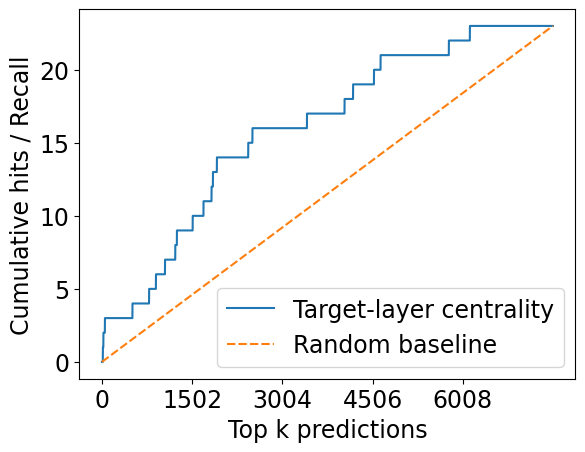

In [15]:
young_supra = abs(young_supra)
young_target_layer_cen_vector = right_target_global_centrality_t(young_supra.values, num_layers=2, target_tissue = 1, target_gene_indices = target_genes_indices, p=0.9)
young_target_layer_results, young_filtered_results, young_plot_df = plot_target_layer_k_curve(genes, young_target_layer_cen_vector[1], 
                                                                                              common_source_genes)

In [55]:
# # Computation of local-set and query-set centrality vectors
# import copy
# supra = abs(young_supra)
# young_A = np.zeros_like(young_supra.values)
# young_A[:n,:n] = supra.values[n:,n:]
# young_A[:n,n:] = supra.values[n:,:n]
# young_A[n:,:n] = supra.values[:n,n:]
# young_A[n:,n:] = supra.values[:n,:n]
# young_target_layer_cen_vector = target_layer_centrality(young_A, num_layers=2, target_tissue = 1, target_gene_indices = source_genes_indices, p=0.9)
# young_target_layer_results, young_filtered_results, young_plot_df = plot_target_layer_k_curve(genes, young_target_layer_cen_vector, 
#                                                                             common_target_genes)

##### Aged

In [16]:
N = int(aged_supra.shape[0])
L = 2
n = int(N/L)

genes = list(aged_supra.columns[:n])
source_genes = hepatokine_genes
target_genes = liver_to_brain_receptor_genes

print("Statistics of the ground truth data")
print("Number of genes: ", len(genes))
print("Number of target genes: ", len(target_genes))
print("Number of source genes: ", len(source_genes))
#print(genes)


common_source_genes = np.intersect1d(genes, source_genes)
common_target_genes = np.intersect1d(genes, target_genes)

print("Number of target genes present in the data: ", len(common_target_genes))
print("Number of source genes present in the data: ", len(common_source_genes))

target_genes_indices = [i for i, e in enumerate(genes) if e in common_target_genes]
source_genes_indices = [i for i, e in enumerate(genes) if e in common_source_genes]

Statistics of the ground truth data
Number of genes:  7510
Number of target genes:  67
Number of source genes:  79
Number of target genes present in the data:  36
Number of source genes present in the data:  23


target tissue id
1
right_new_local_centrality
local centrality computation starts
0
[0.         0.         0.33958301]
1
[0.         0.33958301 0.12262783]
2
[0.33958301 0.12262783 0.06577613]
3
[0.12262783 0.06577613 0.03628962]
4
[0.06577613 0.03628962 0.01973464]
5
[0.03628962 0.01973464 0.01066957]
6
[0.01973464 0.01066957 0.00575368]
7
[0.01066957 0.00575368 0.0030989 ]
8
[0.00575368 0.0030989  0.001668  ]
9
[0.0030989  0.001668   0.00089752]
10
[0.001668   0.00089752 0.00048286]
11
[0.00089752 0.00048286 0.00025975]
12
[0.00048286 0.00025975 0.00013972]
13
[2.59750258e-04 1.39723645e-04 7.51575293e-05]
14
[1.39723645e-04 7.51575293e-05 4.04267569e-05]
15
[7.51575293e-05 4.04267569e-05 2.17451344e-05]
16
[4.04267569e-05 2.17451344e-05 1.16965003e-05]
17
[2.17451344e-05 1.16965003e-05 6.29136131e-06]
18
[1.16965003e-05 6.29136131e-06 3.38404026e-06]
19
[6.29136131e-06 3.38404026e-06 1.82007787e-06]
20
[3.38404026e-06 1.82007787e-06 9.78837305e-07]
21
[1.82007787e-06 9.78837305e-07 

[6.25138788e-07 5.63098300e-07 5.06858568e-07]
105
4.739274038183888
[5.63098300e-07 5.06858568e-07 4.55644275e-07]
106
4.7392799030431885
[5.06858568e-07 4.55644275e-07 4.10255787e-07]
107
4.739285181416559
[4.55644275e-07 4.10255787e-07 3.68634369e-07]
108
4.739289931952593
[4.10255787e-07 3.68634369e-07 3.31529907e-07]
109
4.739294207435022
[3.68634369e-07 3.31529907e-07 2.99138723e-07]
110
4.7392980553692095
[3.31529907e-07 2.99138723e-07 2.69047470e-07]
111
4.739301518509977
[2.99138723e-07 2.69047470e-07 2.41656225e-07]
112
4.739304635336669
[2.69047470e-07 2.41656225e-07 2.18493913e-07]
113
4.739307440480692
[2.41656225e-07 2.18493913e-07 1.95994175e-07]
114
4.739309965110312
[2.18493913e-07 1.95994175e-07 1.78813934e-07]
115
4.7393122372769705
[1.95994175e-07 1.78813934e-07 1.60490418e-07]
116
4.739314282226963
[1.78813934e-07 1.60490418e-07 1.42148018e-07]
117
4.739316122681956
[1.60490418e-07 1.42148018e-07 1.26440546e-07]
118
4.73931777909145
[1.42148018e-07 1.26440546e-07 1

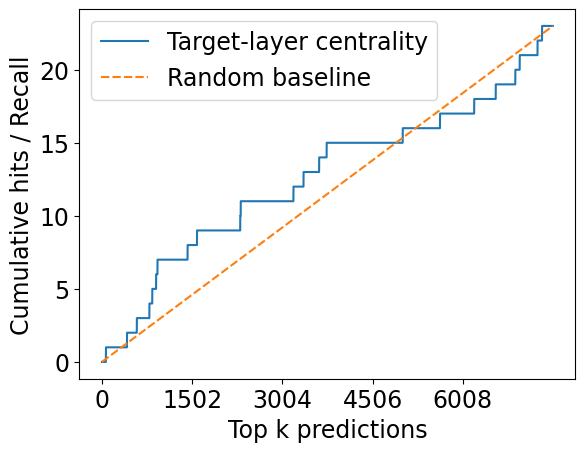

In [17]:
aged_supra = abs(aged_supra)
aged_target_layer_cen_vector = right_target_global_centrality_t(aged_supra.values, num_layers=2, target_tissue = 1, target_gene_indices = target_genes_indices, p=0.9)
aged_target_layer_results, aged_filtered_results, aged_plot_df = plot_target_layer_k_curve(genes, aged_target_layer_cen_vector[1], 
                                                                                              common_source_genes)

In [18]:
# Merge on gene_name
merged = pd.merge(aged_target_layer_results, young_target_layer_results, on='gene_name', suffixes=('_young', '_aged'))
merged['centrality_change'] = merged['centrality_young'] - merged['centrality_aged']
merged = merged.sort_values('centrality_change', ascending=False)
final_df = merged[['gene_name', 'centrality_young', 'centrality_aged', 'centrality_change', 'rank_young', 'rank_aged']]
final_df

,gene_name,centrality_young,centrality_aged,centrality_change,rank_young,rank_aged
57,HYAL2,0.893753,0.564291,0.329462,58,6870
23,VCAN,0.914965,0.586392,0.328574,24,6332
34,SH3TC1,0.907721,0.588942,0.318779,35,6253
113,MEIS2,0.864128,0.547435,0.316693,114,7155
53,RGCC,0.896387,0.590055,0.306332,54,6224
...,...,...,...,...,...,...
6901,TIMM10,0.599871,0.851345,-0.251474,6902,59
7273,MPZL2,0.572942,0.835035,-0.262093,7274,94
7311,IDH2,0.569482,0.843678,-0.274196,7312,74
7373,ALPL,0.561001,0.844424,-0.283423,7374,72


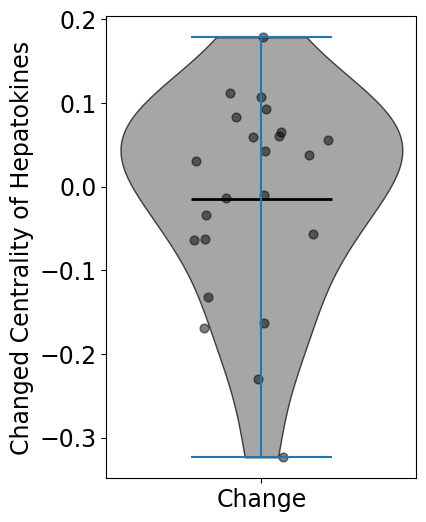

In [56]:
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(4,6))

# Create violin plot
violin = ax.violinplot(df['centrality_change'], showmeans=True)

# Set violin color
for body in violin['bodies']:
    body.set_facecolor('#808080')  # grey
    body.set_edgecolor('black')
    body.set_alpha(0.7)

# Customize mean line
violin['cmeans'].set_color('black')
violin['cmeans'].set_linewidth(2)

# Add jittered black points
y = df['centrality_change'].values
x = np.random.normal(1, 0.08, size=len(y))  # jitter around position 1
ax.scatter(x, y, color='black', alpha=0.5, s=40)

# Labels
ax.set_xticks([1])
ax.set_xticklabels(['Change'])
ax.set_ylabel('Changed Centrality of Hepatokines')
plt.show()


In [54]:
df

,gene_name,centrality_young,centrality_aged,centrality_change,rank_young,rank_aged
902,IGF2,0.771525,0.593003,0.178522,903,6128
66,ANGPTL4,0.884495,0.772136,0.112359,67,509
925,TGFB3,0.770413,0.662977,0.107436,926,3415
417,CCL2,0.807105,0.713842,0.093264,418,1692
3742,TF,0.685973,0.602887,0.083086,3743,5778
838,IL6,0.774530,0.709185,0.065345,839,1826
1426,AGT,0.748548,0.687524,0.061024,1427,2507
581,TGFB1,0.791251,0.731966,0.059285,582,1222
3189,CYP27A1,0.698383,0.642936,0.055447,3190,4183
3617,CSF1,0.688851,0.646167,0.042683,3618,4041
